În proiect avem nevoie de un Model 1 de tip encoder, adaptat prin fine-tuning.

Noi am ales să investigăm două variante ale acestui Model 1:
Experiment	Model	Ce investigăm
1A	XLM-RoBERTa-base	Baseline multilingv, context 512
1B	Legal-XLM-Longformer-base	Encoder juridic, context extins

Aceasta este o extensie a subpunctului privind encoderul, nu înlocuiește cerințele separate pentru modelul few-shot bazat pe LLM și modelul SFT cu LoRA.

# Experimentul 2 – Fine-tuning Legal-XLM-Longformer

## 1. Motivația alegerii modelului

În cadrul acestui proiect studiem clasificarea automată multi-label a documentelor juridice în limba română, utilizând datasetul MultiEURLEX și cele 21 de categorii generale EUROVOC.

În primul experiment am utilizat **XLM-RoBERTa-base**, un model Transformer de tip encoder, preantrenat pe texte multilingve. Modelul a fost adaptat pentru clasificarea multi-label și antrenat utilizând un context maxim de 512 tokeni.

Analiza exploratorie a evidențiat însă o limitare importantă: documentele juridice sunt adesea foarte lungi, iar trunchierea lor la 512 tokeni poate elimina informații relevante pentru identificarea categoriilor.

În cazul XLM-RoBERTa, aproximativ **79,2% dintre documentele de antrenare depășesc limita de 512 tokeni**.

Pentru a investiga această problemă, am ales modelul **`joelniklaus/legal-xlm-longformer-base`**, un encoder multilingv specializat pentru texte juridice, care poate procesa secvențe de până la 4.096 de tokeni.

## 2. De ce Legal-XLM-Longformer?

Alegerea modelului este motivată de trei caracteristici:

1. **Context extins:** permite procesarea a până la 4.096 de tokeni, comparativ cu 512 în experimentul XLM-RoBERTa.
2. **Specializare juridică:** modelul a fost preantrenat pe corpusuri juridice multilingve, ceea ce poate contribui la reprezentarea mai bună a terminologiei și structurilor specifice acestui domeniu.
3. **Mecanism de atenție eficient:** Longformer utilizează atenție locală de tip *sliding window*, combinată cu atenție globală, pentru a procesa secvențe lungi cu un cost mai redus decât atenția completă standard.

Analiza lungimilor documentelor a arătat că numai aproximativ **10,3%** dintre documentele de antrenare depășesc limita de 4.096 de tokeni atunci când utilizăm tokenizerul Legal-XLM-Longformer.

## 3. Obiectivul experimentului

Obiectivul este să investigăm dacă utilizarea unui encoder specializat pentru domeniul juridic, capabil să proceseze contexte mai lungi, îmbunătățește clasificarea documentelor MultiEURLEX față de modelul XLM-RoBERTa-base.

Vom utiliza aceleași partiții train, validation și test, aceleași 21 de categorii și aceleași metrici:

- Micro-F1
- Macro-F1
- Precision și Recall
- F1-score pentru fiecare categorie

La fel ca în primul experiment, pragurile de clasificare vor putea fi selectate utilizând setul de validare, fără folosirea setului de test pentru ajustarea modelului.

## 4. Ipoteza de cercetare

**Ipoteză:** Procesarea unei părți mai mari a documentelor juridice și utilizarea reprezentărilor lingvistice specializate ar putea îmbunătăți performanța clasificării multi-label, în special pentru documentele lungi.

Totuși, această îmbunătățire nu este garantată. Contextul suplimentar poate conține informații nerelevante, iar procesarea secvențelor lungi implică un cost computațional mai ridicat.

## 5. Limitările comparației

Cele două modele diferă atât prin lungimea maximă a contextului, cât și prin datele de preantrenare și arhitectura mecanismului de atenție.

Prin urmare, o eventuală diferență de performanță nu poate fi atribuită exclusiv lungimii contextului.

În plus, experimentul se desfășoară pe un GPU NVIDIA GeForce RTX 5070 Laptop cu aproximativ 8 GB VRAM, ceea ce impune verificarea consumului de memorie și, eventual, adaptarea configurației de antrenare.

**Rezultatul urmărit:** identificarea compromisului dintre performanța clasificării, cantitatea de context procesată și resursele computaționale necesare.

In [5]:

from pathlib import Path
import json
import pandas as pd
import torch
import transformers

DATA_DIR = Path("../Data/processed")
MODELS_DIR = Path("../Models")
RESULTS_DIR = Path("../Results")

MODEL_NAME = "joelniklaus/legal-xlm-longformer-base"

train_df = pd.read_parquet(DATA_DIR / "train.parquet")
val_df = pd.read_parquet(DATA_DIR / "validation.parquet")

with open(DATA_DIR / "label2id.json", encoding="utf-8") as f:
    label2id = json.load(f)

with open(DATA_DIR / "id2label.json", encoding="utf-8") as f:
    id2label = json.load(f)

NUM_LABELS = len(label2id)

print("Model:", MODEL_NAME)
print("Documente train:", len(train_df))
print("Documente validation:", len(val_df))
print("Categorii:", NUM_LABELS)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        ),
        "GB"
    )

assert len(train_df) == 15920
assert len(val_df) == 5000
assert NUM_LABELS == 21

print("\nPregatirea experimentului: reusita")


Model: joelniklaus/legal-xlm-longformer-base
Documente train: 15920
Documente validation: 5000
Categorii: 21
PyTorch: 2.15.0+cu132
Transformers: 5.23.0
CUDA: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
VRAM: 7.96 GB

Pregatirea experimentului: reusita


Inainte sa incarc modelul propriu-zis, vreau sa verific daca pot folosi contextul de 4096 de tokeni si cum e configurat tokenizerul pe care-l foloseste modelul.

Celula 2 – Încărcarea și verificarea tokenizerului Longformer

In [4]:

from transformers import AutoTokenizer, AutoConfig

# Incarcam tokenizerul si configuratia modelului
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
config = AutoConfig.from_pretrained(MODEL_NAME)

print("=== TOKENIZER ===")
print("Tip tokenizer:", type(tokenizer).__name__)
print("Vocabular:", len(tokenizer))
print("Lungime maxima:", tokenizer.model_max_length)
print("Token special CLS:", tokenizer.cls_token)
print("Token special SEP:", tokenizer.sep_token)
print("Token special PAD:", tokenizer.pad_token)

print("\n=== CONFIGURATIE MODEL ===")
print("Tip arhitectura:", config.model_type)
print("Dimensiune reprezentari:", config.hidden_size)
print("Numar straturi:", config.num_hidden_layers)
print("Numar capete de atentie:", config.num_attention_heads)
print(
    "Pozitii maxime:",
    config.max_position_embeddings
)
print(
    "Attention window:",
    getattr(config, "attention_window", None)
)

# Verificam capacitatea de procesare
assert tokenizer.model_max_length >= 4096
assert config.model_type == "longformer"

print("\nTokenizerul este pregatit!")


=== TOKENIZER ===
Tip tokenizer: TokenizersBackend
Vocabular: 128000
Lungime maxima: 4096
Token special CLS: <s>
Token special SEP: </s>
Token special PAD: <pad>

=== CONFIGURATIE MODEL ===
Tip arhitectura: longformer
Dimensiune reprezentari: 768
Numar straturi: 12
Numar capete de atentie: 12
Pozitii maxime: 4098
Attention window: [128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128]

Tokenizerul este pregatit!


Tokenizerul Legal-XLM-Longformer a fost încărcat și verificat cu succes. Avem confirmarea că modelul acceptă secvențe de maximum 4.096 de tokeni, față de cei 512 utilizați în experimentul XLM-RoBERTa.

Ce este important?
Un document de 4.000 de tokeni poate încăpea integral în contextul Longformer, dacă includem și tokenii speciali în limita de 4.096.

În schimb, în experimentul anterior cu XLM-RoBERTa, documentul ar fi fost trunchiat la 512 tokeni.

Totuși, contextul mai lung nu garantează o clasificare mai bună. Tocmai asta vreau să verific experimental.

Următorul pas: pregătirea datelor pentru Longformer

Înainte de antrenare trebuie să construim un Dataset PyTorch, similar celui utilizat la XLM-RoBERTa, dar cu limita de 4.096 de tokeni.

Vom păstra tokenizarea dinamică, astfel încât documentele scurte să nu fie completate inutil până la 4.096 de tokeni.

Celula 3 – Dataset pentru Legal-XLM-Longformer

In [7]:

from torch.utils.data import Dataset
import torch

MAX_LENGTH = 4096

class LegalDocumentDataset(Dataset):
    def __init__(self, dataframe, tokenizer, label2id, max_length):
        self.dataframe = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.label2id = label2id
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        encoding = self.tokenizer(
            row["text"],
            truncation=True,
            max_length=self.max_length,
            padding=False
        )

        labels = torch.zeros(
            len(self.label2id),
            dtype=torch.float32
        )

        for label in row["labels"]:
            labels[self.label2id[str(label)]] = 1.0

        encoding["labels"] = labels

        return encoding


train_dataset = LegalDocumentDataset(
    train_df,
    tokenizer,
    label2id,
    MAX_LENGTH
)

val_dataset = LegalDocumentDataset(
    val_df,
    tokenizer,
    label2id,
    MAX_LENGTH
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

sample = train_dataset[0]

print("Tokeni primul document:", len(sample["input_ids"]))
print("Etichete active:", int(sample["labels"].sum()))

assert len(train_dataset) == 15920
assert len(val_dataset) == 5000
assert len(sample["input_ids"]) <= MAX_LENGTH
assert sample["labels"].shape == (21,)

print("\nDataset pregatit cu succes!")


Train: 15920
Validation: 5000
Tokeni primul document: 676
Etichete active: 5

Dataset pregatit cu succes!


Pentru fiecare document, clasa transformă textul în tokeni și etichetele EUROVOC într-un vector de 21 de valori binare.

De exemplu, dacă un document aparține categoriilor drept, comerț și finanțe, vectorul va avea valoarea 1 la cele trei poziții corespunzătoare și 0 la celelalte 18.

Folosim padding=False deoarece completarea secvențelor va fi făcută ulterior, la nivel de batch.

Un lucru interesant: primul document are 676 de tokeni, deci încape integral în contextul Longformer, dar ar fi fost trunchiat în experimentul XLM-RoBERTa, unde foloseam maximum 512 tokeni.

Totuși, cele două modele folosesc tokenizatoare diferite, deci numărul exact de tokeni nu este direct comparabil.

Important: această celulă nu încarcă încă greutățile modelului în GPU și nu consumă memoria necesară antrenării. După ea voi testa separat dacă 4.096 de tokeni sunt fezabili pe placa mea de 8 GB.

Celula 4 – Pregătirea batch-urilor pentru Longformer

Înainte să încărcăm modelul, trebuie să verificăm că putem grupa documentele în batch-uri.

Voi utiliza DataCollatorWithPadding, ca în experimentul precedent.

Diferența importantă: pentru Longformer vom completa secvențele până la un multiplu de 128, deoarece fiecare strat are o fereastră de atenție configurată la 128. Acest lucru este compatibil cu mecanismul de atenție al modelului.

In [9]:

import torch
from transformers import DataCollatorWithPadding

# Collator pentru tokeni, cu padding dinamic
token_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=128
)

# Collator personalizat pentru clasificare multi-label
def data_collator(features):
    labels = torch.stack([
        feature["labels"] for feature in features
    ])

    token_features = [
        {
            key: value
            for key, value in feature.items()
            if key != "labels"
        }
        for feature in features
    ]

    batch = token_collator(token_features)
    batch["labels"] = labels

    return batch


# Testam doua documente
test_batch = [
    train_dataset[0],
    train_dataset[1]
]

batch = data_collator(test_batch)

print("Dimensiune input_ids:", batch["input_ids"].shape)
print("Dimensiune attention_mask:", batch["attention_mask"].shape)
print("Dimensiune labels:", batch["labels"].shape)

print("\nLungimi originale:")
for i, sample in enumerate(test_batch):
    print(
        f"Document {i + 1}:",
        len(sample["input_ids"]),
        "tokeni"
    )

print("\nLungime dupa padding:", batch["input_ids"].shape[1])

assert batch["input_ids"].shape[0] == 2
assert batch["labels"].shape == (2, 21)
assert batch["labels"].dtype == torch.float32
assert batch["input_ids"].shape[1] % 128 == 0
assert batch["input_ids"].shape[1] <= 4096

print("\nDynamic padding verificat!")


Dimensiune input_ids: torch.Size([2, 4096])
Dimensiune attention_mask: torch.Size([2, 4096])
Dimensiune labels: torch.Size([2, 21])

Lungimi originale:
Document 1: 676 tokeni
Document 2: 3970 tokeni

Lungime dupa padding: 4096

Dynamic padding verificat!


Celula 5 – Încărcarea modelului Legal-XLM-Longformer

Acum încărcăm greutățile preantrenate și adăugăm un strat de clasificare pentru cele 21 de categorii EUROVOC.

In [10]:

from transformers import AutoModelForSequenceClassification
import torch

torch.manual_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    ignore_mismatched_sizes=True
)

model.to("cpu")

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Model:", MODEL_NAME)
print("Arhitectura:", model.config.model_type)
print("Numar categorii:", model.config.num_labels)
print("Tip clasificare:", model.config.problem_type)

print(f"\nParametri totali: {total_params:,}")
print(f"Parametri antrenabili: {trainable_params:,}")

print("\nModel incarcat cu succes!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  834MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

[transformers] LongformerForSequenceClassification LOAD REPORT from: joelniklaus/legal-xlm-longformer-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: joelniklaus/legal-xlm-longformer-base
Arhitectura: longformer
Numar categorii: 21
Tip clasificare: multi_label_classification

Parametri totali: 208,376,085
Parametri antrenabili: 208,376,085

Model incarcat cu succes!


Modelul are două componente importante:
- Encoderul Longformer: transformă documentul juridic într-o reprezentare numerică, folosind ceea ce a învățat în timpul preantrenării.
- Stratul de clasificare: primește reprezentarea documentului și produce 21 de scoruri, câte unul pentru fiecare categorie EUROVOC.
Parametrul problem_type="multi_label_classification" este esențial: același document poate aparține mai multor categorii simultan. Modelul va folosi o funcție de pierdere adecvată acestui tip de problemă.

Celula 6 – Test de memorie GPU, fără antrenare

Începem cu un singur document de 1.024 de tokeni și verificăm dacă putem efectua un pas forward și backward.

Acesta este un test de fezabilitate, nu o etapă de antrenare propriu-zisă. Nu vom apela optimizer.step(), deci nu vom modifica greutățile modelului.

In [11]:

import torch
import gc

# Eliberam memoria neutilizata
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

device = torch.device("cuda")

# Pregatim un singur document, limitat la 1024 tokeni
sample = train_dataset[1]

test_length = 1024

input_ids = torch.tensor(
    sample["input_ids"][:test_length],
    dtype=torch.long
).unsqueeze(0).to(device)

attention_mask = torch.tensor(
    sample["attention_mask"][:test_length],
    dtype=torch.long
).unsqueeze(0).to(device)

labels = sample["labels"].unsqueeze(0).to(device)

# Mutam modelul pe GPU
model = model.to(device)
model.train()

# Activam gradient checkpointing
model.gradient_checkpointing_enable()

try:
    with torch.autocast("cuda", dtype=torch.float16):
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

    loss = outputs.loss
    loss.backward()

    print("Forward + backward: REUSIT")
    print("Loss:", float(loss.detach().cpu()))
    print(
        "Memorie maxima alocata:",
        round(
            torch.cuda.max_memory_allocated()
            / (1024 ** 3), 2
        ),
        "GB"
    )

    print(
        "Memorie maxima rezervata:",
        round(
            torch.cuda.max_memory_reserved()
            / (1024 ** 3), 2
        ),
        "GB"
    )

finally:
    model.zero_grad(set_to_none=True)
    del outputs, loss, input_ids, attention_mask, labels
    gc.collect()
    torch.cuda.empty_cache()


/home/emilovici/projects/NLP-Master/.venv311/lib/python3.11/site-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
[transformers] Initializing global attention on CLS token...
In file included from /home/emilovici/.local/share/uv/python/cpython-3.11.18-linux-x86_64-gnu/include/python3.11/Python.h:12,
                 from /home/emilovici/projects/NLP-Master/.venv311/lib/python3.11/site-packages/triton/backends/nvidia/driver.c:9:
/home/emilovici/.local/share/uv/python/cpython-3.11.18-linux-x86_64-gnu/include/python3.11/pyconfig.h:1796:9: warning: ‘_POSIX_C_SOURCE’ redefined
 1796 | #define _POSIX_C_SOURCE 200809L
      |         ^~~~~~~~~~~~~~~
In file included from /usr/include/x86_64-linux-gnu/bits/libc-header-start.h:33,
                 from /usr/include/stdlib.h:26,
                 from /home/emilovici/projects/NLP-Master/.venv311/lib/

Forward + backward: REUSIT
Loss: 0.6777553558349609
Memorie maxima alocata: 1.58 GB
Memorie maxima rezervata: 1.72 GB


Celula 7 – Antrenarea completă Legal-XLM-Longformer

Aleg momentan 2.048 în loc de 4.096 pentru că am numai 8 GB VRAM. Este în continuare un context de patru ori mai mare decât cel folosit la XLM-RoBERTa, dar nu reprezintă experimentul la capacitatea maximă a modelului. Nu putem garanta că va încăpea în memorie până nu pornește efectiv.

In [12]:

import gc
import json
import shutil
from pathlib import Path

import numpy as np
import torch

from sklearn.metrics import f1_score, precision_score, recall_score

from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed
)

# ==========================================
# 1. CONFIGURARE
# ==========================================

set_seed(42)

MAX_LENGTH = 2048

MODELS_DIR = Path("../Models")
RESULTS_DIR = Path("../Results")

TEMP_DIR = MODELS_DIR / ".legal_xlm_longformer_checkpoints"
FINAL_DIR = MODELS_DIR / "legal_xlm_longformer_best"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. REINITIALIZARE MODEL
# ==========================================

# Ne asiguram ca pornim de la greutatile
# originale preantrenate, nu de la testele GPU.

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification"
)

model.gradient_checkpointing_enable()

# ==========================================
# 3. LIMITA DE TOKENI
# ==========================================

# Dataseturile existente folosesc acelasi
# tokenizer, dar acum trunchiem la 2048.

train_dataset.max_length = MAX_LENGTH
val_dataset.max_length = MAX_LENGTH

# ==========================================
# 4. METRICI MULTI-LABEL
# ==========================================

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    probabilities = 1 / (
        1 + np.exp(-np.clip(logits, -50, 50))
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    labels = labels.astype(int)

    return {
        "micro_f1": f1_score(
            labels, predictions,
            average="micro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),
        "micro_precision": precision_score(
            labels, predictions,
            average="micro",
            zero_division=0
        ),
        "micro_recall": recall_score(
            labels, predictions,
            average="micro",
            zero_division=0
        )
    }

# ==========================================
# 5. ARGUMENTE ANTRENARE
# ==========================================

training_args = TrainingArguments(
    output_dir=str(TEMP_DIR),

    num_train_epochs=6,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    gradient_accumulation_steps=8,
    gradient_checkpointing=True,

    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=0.1,

    fp16=True,
    max_grad_norm=1.0,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="micro_f1",
    greater_is_better=True,

    save_total_limit=1,

    seed=42,
    data_seed=42,

    dataloader_num_workers=0,
    report_to="none"
)

# ==========================================
# 6. TRAINER
# ==========================================

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

# ==========================================
# 7. ANTRENARE
# ==========================================

print("Pornim antrenarea Legal-XLM-Longformer.")
print("Documente train:", len(train_dataset))
print("Documente validation:", len(val_dataset))
print("Context:", MAX_LENGTH)
print("Epoci maxime:", training_args.num_train_epochs)
print("GPU:", torch.cuda.get_device_name(0))

train_result = trainer.train()

print("\nAntrenare finalizata!")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Micro-F1:", trainer.state.best_metric)

# ==========================================
# 8. SALVARE MODEL FINAL
# ==========================================

trainer.save_model(str(FINAL_DIR))
tokenizer.save_pretrained(str(FINAL_DIR))

experiment_info = {
    "model": MODEL_NAME,
    "task": "multi_label_classification",
    "num_labels": NUM_LABELS,
    "max_length": MAX_LENGTH,
    "max_epochs": 6,
    "learning_rate": 2e-5,
    "best_validation_micro_f1": float(
        trainer.state.best_metric
    ),
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "threshold": 0.5
}

with open(
    FINAL_DIR / "experiment_info.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        experiment_info,
        f,
        indent=2,
        ensure_ascii=False
    )

# Salvam istoricul in Results
history_path = (
    RESULTS_DIR /
    "legal_xlm_longformer_training_history.json"
)

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(
        trainer.state.log_history,
        f,
        indent=2,
        ensure_ascii=False
    )

# ==========================================
# 9. CURATARE CHECKPOINT-URI
# ==========================================

assert (FINAL_DIR / "model.safetensors").is_file()
assert (FINAL_DIR / "config.json").is_file()
assert (FINAL_DIR / "experiment_info.json").is_file()
assert history_path.is_file()

# Stergem checkpoint-urile temporare
# numai dupa salvarea modelului final.
if TEMP_DIR.exists():
    shutil.rmtree(TEMP_DIR)

print("\n=== EXPERIMENT FINALIZAT ===")
print("Model final:", FINAL_DIR.resolve())
print("Istoric:", history_path.resolve())
print("Best Micro-F1:", trainer.state.best_metric)
print("Checkpoint-uri temporare eliminate.")


Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

[transformers] LongformerForSequenceClassification LOAD REPORT from: joelniklaus/legal-xlm-longformer-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/home/emilovici/projects/NLP-Master/.venv311/lib/python3.11/site-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated 

Pornim antrenarea Legal-XLM-Longformer.
Documente train: 15920
Documente validation: 5000
Context: 2048
Epoci maxime: 6
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Micro Precision,Micro Recall
1,2.312240,0.190708,0.790189,0.570354,0.881538,0.715994
2,1.332916,0.170952,0.816379,0.641380,0.880465,0.760989
3,1.102136,0.161761,0.831670,0.686347,0.873258,0.793862
4,0.951145,0.160134,0.834971,0.704675,0.872841,0.800251
5,0.836984,0.158564,0.837104,0.717111,0.864811,0.811118
6,0.756227,0.160997,0.836937,0.721595,0.864950,0.810681


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Antrenare finalizata!
Best checkpoint: ../Models/.legal_xlm_longformer_checkpoints/checkpoint-9950
Best validation Micro-F1: 0.8371044549015187


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== EXPERIMENT FINALIZAT ===
Model final: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Models/legal_xlm_longformer_best
Istoric: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/legal_xlm_longformer_training_history.json
Best Micro-F1: 0.8371044549015187
Checkpoint-uri temporare eliminate.


Celula 8 – Predicțiile Longformer pe validation

In [13]:

import numpy as np
from pathlib import Path
from sklearn.metrics import f1_score

RESULTS_DIR = Path("../Results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Trainer a reincarcat automat checkpoint-ul
# cu cel mai bun Micro-F1 (epoca 5).

prediction_output = trainer.predict(val_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids.astype(int)

# Transformam logits in probabilitati
y_prob = 1 / (
    1 + np.exp(-np.clip(logits, -50, 50))
)

# Pragul implicit
y_pred = (y_prob >= 0.5).astype(int)

micro_f1 = f1_score(
    y_true, y_pred,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

assert y_prob.shape == (5000, 21)
assert y_true.shape == (5000, 21)
assert np.isfinite(y_prob).all()

# Verificam corespondenta cu modelul selectat
assert np.isclose(
    micro_f1,
    trainer.state.best_metric,
    atol=1e-4
), "Scorul difera de checkpoint-ul selectat!"

# Salvam probabilitatile si etichetele reale
output_path = (
    RESULTS_DIR /
    "legal_xlm_longformer_validation_predictions.npz"
)

np.savez_compressed(
    output_path,
    probabilities=y_prob,
    labels=y_true
)

print("=== EVALUARE MODEL FINAL ===")
print("Documente evaluate:", len(y_true))
print(f"Micro-F1: {micro_f1:.6f}")
print(f"Macro-F1: {macro_f1:.6f}")
print("Checkpoint selectat:", trainer.state.best_model_checkpoint)
print("Predictii salvate:", output_path.resolve())


=== EVALUARE MODEL FINAL ===
Documente evaluate: 5000
Micro-F1: 0.837104
Macro-F1: 0.717111
Checkpoint selectat: ../Models/.legal_xlm_longformer_checkpoints/checkpoint-9950
Predictii salvate: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/legal_xlm_longformer_validation_predictions.npz


Celula 9 – Optimizarea pragului global

Voi testa aceleași 17 praguri ca la XLM-RoBERTa, de la 0.10 la 0.90, cu pasul 0.05.

Astfel, păstrăm o metodologie consecventă între cele două modele.

In [14]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

thresholds = np.round(
    np.arange(0.10, 0.91, 0.05),
    2
)

results = []

for threshold in thresholds:
    predictions = (
        y_prob >= threshold
    ).astype(int)

    results.append({
        "threshold": float(threshold),
        "micro_f1": f1_score(
            y_true,
            predictions,
            average="micro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

print("=== PRAGURI GLOBALE LONGFORMER ===")
print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

best_micro = threshold_df.loc[
    threshold_df["micro_f1"].idxmax()
]

best_macro = threshold_df.loc[
    threshold_df["macro_f1"].idxmax()
]

print("\nCel mai bun prag pentru Micro-F1:")
print(best_micro.to_string())

print("\nCel mai bun prag pentru Macro-F1:")
print(best_macro.to_string())


=== PRAGURI GLOBALE LONGFORMER ===
 threshold  micro_f1  macro_f1
  0.100000  0.777460  0.679950
  0.150000  0.805292  0.710035
  0.200000  0.820161  0.724063
  0.250000  0.826246  0.725675
  0.300000  0.831648  0.727193
  0.350000  0.834410  0.725414
  0.400000  0.836775  0.722619
  0.450000  0.837415  0.720935
  0.500000  0.837104  0.717111
  0.550000  0.836193  0.710912
  0.600000  0.834073  0.704384
  0.650000  0.831023  0.694617
  0.700000  0.826957  0.679737
  0.750000  0.819043  0.665027
  0.800000  0.810437  0.645908
  0.850000  0.792793  0.616741
  0.900000  0.753477  0.555251

Cel mai bun prag pentru Micro-F1:
threshold    0.450000
micro_f1     0.837415
macro_f1     0.720935

Cel mai bun prag pentru Macro-F1:
threshold    0.300000
micro_f1     0.831648
macro_f1     0.727193


La XLM-RoBERTa am analizat și pragurile individuale pentru cele 21 de categorii. Trebuie să facem exact același lucru și pentru Longformer, folosind aceeași grilă de praguri și aceeași metrică de optimizare.

Altfel, comparația nu ar fi complet echitabilă.

Celula 10 – Optimizarea pragurilor individuale Longformer

Folosim exact protocolul din experimentul XLM-RoBERTa:
- Aceleași 21 de categorii EUROVOC.
- Praguri între 0.10 și 0.90, cu pasul 0.05.
- Optimizarea F1 individual pentru fiecare categorie.
- Evaluarea Micro-F1 și Macro-F1 rezultate.

In [16]:

import json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Incarcam denumirile categoriilor EUROVOC
with open(
    "../Data/eurovoc_descriptors.json",
    "r",
    encoding="utf-8"
) as f:
    descriptors = json.load(f)

thresholds = np.round(
    np.arange(0.10, 0.91, 0.05),
    2
)

per_label_results = []

for i in range(NUM_LABELS):
    label_id = str(id2label[str(i)])

    true_labels = y_true[:, i]
    probabilities = y_prob[:, i]

    scores = []

    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        score = f1_score(
            true_labels,
            predictions,
            zero_division=0
        )

        scores.append(score)

    best_index = int(np.argmax(scores))

    per_label_results.append({
        "label_id": label_id,
        "category": descriptors[label_id]["ro"],
        "support": int(true_labels.sum()),
        "threshold": float(thresholds[best_index]),
        "f1_at_0_5": f1_score(
            true_labels,
            (probabilities >= 0.5).astype(int),
            zero_division=0
        ),
        "best_validation_f1": float(scores[best_index])
    })

per_label_df = pd.DataFrame(per_label_results)

print(
    per_label_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Aplicam pragurile individuale
optimal_thresholds = per_label_df["threshold"].to_numpy()

predictions_per_label = (
    y_prob >= optimal_thresholds[None, :]
).astype(int)

micro_per_label = f1_score(
    y_true,
    predictions_per_label,
    average="micro",
    zero_division=0
)

macro_per_label = f1_score(
    y_true,
    predictions_per_label,
    average="macro",
    zero_division=0
)

print("\n=== PRAGURI INDIVIDUALE LONGFORMER ===")
print(f"Micro-F1: {micro_per_label:.6f}")
print(f"Macro-F1: {macro_per_label:.6f}")


label_id                               category  support  threshold  f1_at_0_5  best_validation_f1
  100142                               politică      408     0.2500     0.4900              0.5483
  100143                 relaţii internaţionale      944     0.5000     0.8208              0.8208
  100144                      UNIUNEA EUROPEANĂ     1499     0.3500     0.8159              0.8171
  100145                                  drept      571     0.4000     0.7031              0.7116
  100146                               economie      478     0.2500     0.7031              0.7584
  100147                                 comerţ     2690     0.5500     0.8777              0.8786
  100148                                finanţe     1211     0.5500     0.8923              0.8964
  100149                       probleme sociale      778     0.5000     0.7624              0.7624
  100150     educaţie comunicare şi comunicaţii      469     0.4500     0.6487              0.6522
  100151  

Celula 11 – Salvăm configurația Longformer pentru comparația finală

In [17]:

import json
import numpy as np
from pathlib import Path
from sklearn.metrics import f1_score

MODEL_DIR = Path("../Models/legal_xlm_longformer_best")
RESULTS_DIR = Path("../Results")

# Ordinea etichetelor utilizata de model
label_order = [str(id2label[str(i)]) for i in range(NUM_LABELS)]

assert label_order == per_label_df["label_id"].astype(str).tolist()
assert (MODEL_DIR / "model.safetensors").is_file()

# Selectam pragul global care maximizeaza Micro-F1
best_global_row = threshold_df.loc[
    threshold_df["micro_f1"].idxmax()
]

global_threshold = float(best_global_row["threshold"])

# Preluam pragurile individuale, in ordinea corecta
per_label_thresholds = {
    str(row["label_id"]): float(row["threshold"])
    for _, row in per_label_df.iterrows()
}

# Calculam metricile direct din predictiile existente
def get_f1_scores(predictions):
    return {
        "micro_f1": float(f1_score(
            y_true, predictions,
            average="micro", zero_division=0
        )),
        "macro_f1": float(f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ))
    }

default_scores = get_f1_scores(
    (y_prob >= 0.5).astype(int)
)

global_scores = get_f1_scores(
    (y_prob >= global_threshold).astype(int)
)

individual_threshold_array = np.array([
    per_label_thresholds[label]
    for label in label_order
])

individual_scores = get_f1_scores(
    (y_prob >= individual_threshold_array[None, :]).astype(int)
)

threshold_config = {
    "model": MODEL_NAME,
    "selection_dataset": "validation",
    "selection_documents": len(y_true),
    "selection_metric": "micro_f1",
    "label_order": label_order,
    "default_threshold": 0.5,
    "selected_global_threshold": global_threshold,
    "per_label_thresholds": per_label_thresholds,
    "validation_results": {
        "default": default_scores,
        "global": global_scores,
        "per_label": individual_scores
    }
}

# Salvam configuratia langa model
config_path = MODEL_DIR / "threshold_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        threshold_config, f,
        indent=2, ensure_ascii=False
    )

# Salvam tabelul detaliat in Results
csv_path = RESULTS_DIR / "legal_xlm_longformer_thresholds.csv"

per_label_df.to_csv(
    csv_path, index=False, encoding="utf-8"
)

# Verificam salvarea
with open(config_path, encoding="utf-8") as f:
    saved_config = json.load(f)

assert len(saved_config["label_order"]) == 21
assert len(saved_config["per_label_thresholds"]) == 21
assert saved_config["selected_global_threshold"] == 0.45
assert csv_path.is_file()

print("=== CONFIGURATIE LONGFORMER SALVATA ===")
print("JSON:", config_path.resolve())
print("CSV:", csv_path.resolve())
print("Prag global selectat:", global_threshold)
print("Ordinea etichetelor verificata:", len(label_order))

print("\n=== REZULTATE VALIDATION ===")
for strategy, scores in threshold_config["validation_results"].items():
    print(
        f"{strategy}: "
        f"Micro-F1={scores['micro_f1']:.6f}, "
        f"Macro-F1={scores['macro_f1']:.6f}"
    )


=== CONFIGURATIE LONGFORMER SALVATA ===
JSON: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Models/legal_xlm_longformer_best/threshold_config.json
CSV: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/legal_xlm_longformer_thresholds.csv
Prag global selectat: 0.45
Ordinea etichetelor verificata: 21

=== REZULTATE VALIDATION ===
default: Micro-F1=0.837104, Macro-F1=0.717111
global: Micro-F1=0.837415, Macro-F1=0.720935
per_label: Micro-F1=0.838881, Macro-F1=0.737662


Rezultatele comparative pe validation

Strategie	XLM-RoBERTa	Legal-XLM-Longformer

Micro-F1, prag 0,50	0,817280	0,837104

Macro-F1, prag 0,50	0,663627	0,717111

Micro-F1, prag global optimizat	0,820872	0,837415

Macro-F1, prag global optimizat	0,681307	0,720935

Micro-F1, praguri individuale	0,824327	0,838881

Macro-F1, praguri individuale	0,709838	0,737662

Longformer este superior în toate configurațiile testate pe validation.

Celula 12 – Verificarea compatibilității evaluărilor

In [19]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../Data/processed")
MODELS_DIR = Path("../Models")
RESULTS_DIR = Path("../Results")

# Configuratia XLM-RoBERTa
with open(
    MODELS_DIR / "xlm_roberta_best/threshold_config.json",
    encoding="utf-8"
) as f:
    xlm_config = json.load(f)

# Configuratia Longformer
with open(
    MODELS_DIR / "legal_xlm_longformer_best/threshold_config.json",
    encoding="utf-8"
) as f:
    longformer_config = json.load(f)

# Ordinea oficiala a etichetelor
with open(
    DATA_DIR / "id2label.json",
    encoding="utf-8"
) as f:
    label_mapping = json.load(f)

official_label_order = [
    str(label_mapping[str(i)])
    for i in range(21)
]

# Verificam cele 21 de etichete
assert longformer_config["label_order"] == official_label_order

assert set(
    xlm_config["per_label_thresholds"]
) == set(official_label_order)

assert set(
    longformer_config["per_label_thresholds"]
) == set(official_label_order)

# Verificam configuratiile principale
print("=== CONFIGURATII SELECTATE ===")

print(
    "XLM-RoBERTa - prag global:",
    xlm_config["selected_global_threshold"]
)

print(
    "Longformer - prag global:",
    longformer_config["selected_global_threshold"]
)

print("\nCategorii EUROVOC:", len(official_label_order))
print("Documente validation:", len(val_df))

assert len(val_df) == 5000

print("\nConfiguratiile sunt compatibile!")


=== CONFIGURATII SELECTATE ===
XLM-RoBERTa - prag global: 0.4
Longformer - prag global: 0.45

Categorii EUROVOC: 21
Documente validation: 5000

Configuratiile sunt compatibile!


Celula 13 – Compararea celor 21 de categorii

Vom calcula F1 pentru fiecare categorie folosind pragurile globale selectate. Pentru XLM-RoBERTa trebuie să reconstruim predicțiile, deoarece am salvat raportul la pragul 0.5, nu probabilitățile individuale.

Nu reantrenăm XLM-RoBERTa. Îl încărcăm din Models/xlm_roberta_best și efectuăm doar inferență pe validation.

In [20]:

import gc
import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Configuratii
XLM_DIR = Path("../Models/xlm_roberta_best")
RESULTS_DIR = Path("../Results")

xlm_tokenizer = AutoTokenizer.from_pretrained(
    str(XLM_DIR)
)

xlm_model = AutoModelForSequenceClassification.from_pretrained(
    str(XLM_DIR)
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Eliberam memoria folosita de Longformer
if "trainer" in globals():
    del trainer

if "model" in globals():
    del model

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

xlm_model = xlm_model.to(device)
xlm_model.eval()

# Verificam ordinea etichetelor Longformer
expected_labels = np.zeros_like(y_true)

for row_idx, labels in enumerate(val_df["labels"]):
    for label in labels:
        label_index = official_label_order.index(str(label))
        expected_labels[row_idx, label_index] = 1

assert np.array_equal(
    expected_labels,
    y_true
), "Etichetele Longformer nu corespund ordinii validation!"

# Predictii XLM-RoBERTa
xlm_probabilities = []

with torch.inference_mode():
    for text in tqdm(val_df["text"], desc="XLM-RoBERTa validation"):
        inputs = xlm_tokenizer(
            text,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        outputs = xlm_model(**inputs)

        probs = torch.sigmoid(
            outputs.logits.float()
        ).cpu().numpy()[0]

        xlm_probabilities.append(probs)

xlm_probabilities = np.array(xlm_probabilities)

assert xlm_probabilities.shape == (5000, 21)

# Verificam scorul anterior
xlm_pred_global = (
    xlm_probabilities >= 0.40
).astype(int)

xlm_micro = f1_score(
    expected_labels,
    xlm_pred_global,
    average="micro",
    zero_division=0
)

assert np.isclose(
    xlm_micro,
    0.820872,
    atol=1e-4
)

# Longformer, cu pragul sau global
longformer_pred_global = (
    y_prob >= 0.45
).astype(int)

# Calculam F1 pentru fiecare categorie
rows = []

for i, label_id in enumerate(official_label_order):
    rows.append({
        "label_id": label_id,
        "category": descriptors[label_id]["ro"],
        "support": int(expected_labels[:, i].sum()),
        "xlm_f1": f1_score(
            expected_labels[:, i],
            xlm_pred_global[:, i],
            zero_division=0
        ),
        "longformer_f1": f1_score(
            expected_labels[:, i],
            longformer_pred_global[:, i],
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(rows)

comparison_df["difference"] = (
    comparison_df["longformer_f1"]
    - comparison_df["xlm_f1"]
)

comparison_path = (
    RESULTS_DIR / "encoder_per_category_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8"
)

print(
    comparison_df.sort_values(
        "difference",
        ascending=False
    ).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nComparatie salvata:", comparison_path.resolve())
print("Micro-F1 XLM:", round(xlm_micro, 6))
print(
    "Micro-F1 Longformer:",
    round(
        f1_score(
            expected_labels,
            longformer_pred_global,
            average="micro",
            zero_division=0
        ),
        6
    )
)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

XLM-RoBERTa validation:   0%|          | 0/5000 [00:00<?, ?it/s]

label_id                               category  support  xlm_f1  longformer_f1  difference
  100162             organizaţii internaţionale       69  0.0244         0.3030      0.2786
  100151                                ştiinţă       65  0.0303         0.1905      0.1602
  100160                              industrie      568  0.6977         0.7556      0.0579
  100158     producţie, tehnologie şi cercetare      578  0.5935         0.6378      0.0443
  100142                               politică      408  0.4672         0.5104      0.0432
  100145                                  drept      571  0.6732         0.7111      0.0379
  100148                                finanţe     1211  0.8573         0.8919      0.0346
  100144                      UNIUNEA EUROPEANĂ     1499  0.7860         0.8158      0.0298
  100159                                energie      154  0.7045         0.7341      0.0295
  100153 angajare în muncă şi condiţii de muncă      203  0.5976         0.6200 

Celula 14 – Salvarea deciziei de selecție

In [21]:

import json
from pathlib import Path

RESULTS_DIR = Path("../Results")

selection = {
    "task": "MultiEURLEX multi-label classification",
    "selection_dataset": "validation",
    "selection_metric": "micro_f1",
    "test_used_for_selection": False,
    "comparison_protocol": {
        "same_documents": True,
        "same_label_order": True,
        "threshold_selection": "global_micro_f1",
        "threshold_grid": [
            round(x * 0.05, 2)
            for x in range(2, 19)
        ]
    },
    "models": {
        "xlm_roberta": {
            "path": "../Models/xlm_roberta_best",
            "max_length": 512,
            "global_threshold": 0.40,
            "validation_micro_f1": 0.820872,
            "validation_macro_f1": 0.681307
        },
        "legal_xlm_longformer": {
            "path": "../Models/legal_xlm_longformer_best",
            "max_length": 2048,
            "global_threshold": 0.45,
            "validation_micro_f1": 0.837415,
            "validation_macro_f1": 0.720935
        }
    },
    "selected_encoder": "legal_xlm_longformer",
    "selection_reason": (
        "Highest validation Micro-F1 under the same "
        "global threshold optimization protocol"
    )
}

output_path = RESULTS_DIR / "encoder_model_selection.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(selection, f, indent=2, ensure_ascii=False)

with open(output_path, encoding="utf-8") as f:
    saved = json.load(f)

assert saved["selected_encoder"] == "legal_xlm_longformer"
assert saved["test_used_for_selection"] is False

print("Selectie salvata:", output_path.resolve())
print("Encoder selectat:", saved["selected_encoder"])
print("Metrica de selectie:", saved["selection_metric"])
print("Setul de test a fost folosit:", saved["test_used_for_selection"])


Selectie salvata: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/encoder_model_selection.json
Encoder selectat: legal_xlm_longformer
Metrica de selectie: micro_f1
Setul de test a fost folosit: False


Celula 15 – Pregătirea evaluării pe test

In [23]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../Data/processed")
RESULTS_DIR = Path("../Results")

# Incarcam setul de test original
test_df = pd.read_parquet(DATA_DIR / "test.parquet")

# Incarcam configuratia de selectie
with open(
    RESULTS_DIR / "encoder_model_selection.json",
    encoding="utf-8"
) as f:
    selection = json.load(f)

# Ordinea oficiala a celor 21 de categorii
with open(
    DATA_DIR / "id2label.json",
    encoding="utf-8"
) as f:
    id2label_test = json.load(f)

label_order = [
    str(id2label_test[str(i)])
    for i in range(21)
]

# Construim etichetele reale in ordinea oficiala
label_index = {
    label: i for i, label in enumerate(label_order)
}

y_test = np.zeros(
    (len(test_df), len(label_order)),
    dtype=np.int32
)

for row_idx, labels in enumerate(test_df["labels"]):
    for label in labels:
        y_test[row_idx, label_index[str(label)]] = 1

# Verificari
assert len(test_df) == 5000
assert y_test.shape == (5000, 21)
assert selection["test_used_for_selection"] is False

print("=== PREGATIRE EVALUARE TEST ===")
print("Documente test:", len(test_df))
print("Categorii:", len(label_order))
print("Forma etichetelor:", y_test.shape)
print("Total etichete pozitive:", int(y_test.sum()))

print("\n=== CONFIGURATII FIXATE ===")

for model_name, config in selection["models"].items():
    print(
        f"{model_name}: "
        f"context={config['max_length']}, "
        f"prag={config['global_threshold']}"
    )

print("\nModel selectat pe validation:", selection["selected_encoder"])
print("Setul de test nu a fost folosit pentru selectie.")


=== PREGATIRE EVALUARE TEST ===
Documente test: 5000
Categorii: 21
Forma etichetelor: (5000, 21)
Total etichete pozitive: 17969

=== CONFIGURATII FIXATE ===
xlm_roberta: context=512, prag=0.4
legal_xlm_longformer: context=2048, prag=0.45

Model selectat pe validation: legal_xlm_longformer
Setul de test nu a fost folosit pentru selectie.


Setul de test este pregătit corect, iar configurațiile ambelor modele au fost fixate înainte de evaluare.

Avem:
- 5.000 de documente de test.
- 21 de categorii EUROVOC.
- 17.969 de etichete pozitive, deoarece un document poate aparține mai multor categorii.
- Legal-XLM-Longformer selectat pe validation, cu Micro-F1 = 0,837415.
Acum facem evaluarea independentă, fără antrenare și fără modificarea pragurilor.

Celula 16 – Inferența XLM-RoBERTa pe test

Vom evalua mai întâi XLM-RoBERTa, folosind modelul final salvat, contextul de 512 tokeni și pragul global 0.40.

Salvăm probabilitățile pentru a putea calcula ulterior toate metricile fără să repetăm inferența.

In [24]:

import gc
import numpy as np
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Configuratia fixata pe validation
xlm_config = selection["models"]["xlm_roberta"]

XLM_DIR = Path(xlm_config["path"])
XLM_MAX_LENGTH = int(xlm_config["max_length"])
XLM_THRESHOLD = float(xlm_config["global_threshold"])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Eliberam modelele anterioare din memorie
for variable_name in ["trainer", "model", "xlm_model"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Incarcam modelul final XLM-RoBERTa
xlm_tokenizer = AutoTokenizer.from_pretrained(
    str(XLM_DIR)
)

xlm_model = AutoModelForSequenceClassification.from_pretrained(
    str(XLM_DIR)
).to(device)

xlm_model.eval()

# Verificam configuratia
assert xlm_model.config.num_labels == 21
assert XLM_MAX_LENGTH == 512
assert XLM_THRESHOLD == 0.40

# Predictii pentru toate documentele de test
xlm_test_probabilities = []

with torch.inference_mode():
    for text in tqdm(
        test_df["text"],
        desc="XLM-RoBERTa - Test"
    ):
        inputs = xlm_tokenizer(
            text,
            truncation=True,
            max_length=XLM_MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        outputs = xlm_model(**inputs)

        probabilities = torch.sigmoid(
            outputs.logits.float()
        ).cpu().numpy()[0]

        xlm_test_probabilities.append(probabilities)

xlm_test_probabilities = np.asarray(
    xlm_test_probabilities,
    dtype=np.float32
)

# Verificari
assert xlm_test_probabilities.shape == y_test.shape
assert np.isfinite(xlm_test_probabilities).all()

# Aplicam pragul fixat anterior
xlm_test_predictions = (
    xlm_test_probabilities >= XLM_THRESHOLD
).astype(int)

# Calculam metricile fara a modifica pragul
xlm_test_micro = f1_score(
    y_test,
    xlm_test_predictions,
    average="micro",
    zero_division=0
)

xlm_test_macro = f1_score(
    y_test,
    xlm_test_predictions,
    average="macro",
    zero_division=0
)

# Salvam probabilitatile
output_path = (
    RESULTS_DIR / "xlm_roberta_test_predictions.npz"
)

np.savez_compressed(
    output_path,
    probabilities=xlm_test_probabilities,
    labels=y_test,
    label_order=np.array(label_order)
)

print("\n=== XLM-ROBERTA - TEST ===")
print("Documente evaluate:", len(y_test))
print("Prag utilizat:", XLM_THRESHOLD)
print(f"Micro-F1: {xlm_test_micro:.6f}")
print(f"Macro-F1: {xlm_test_macro:.6f}")
print("Predictii salvate:", output_path.resolve())


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

XLM-RoBERTa - Test:   0%|          | 0/5000 [00:00<?, ?it/s]


=== XLM-ROBERTA - TEST ===
Documente evaluate: 5000
Prag utilizat: 0.4
Micro-F1: 0.786074
Macro-F1: 0.646729
Predictii salvate: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/xlm_roberta_test_predictions.npz


De ce evaluăm separat modelele?

Pentru că au dimensiuni și cerințe de memorie diferite. Încărcăm câte un model pe GPU și salvăm predicțiile, evitând să ocupăm memoria cu ambele simultan.

Următoarea celulă – Evaluarea Legal-XLM-Longformer pe test

Acum evaluăm Longformer folosind exact aceleași 5.000 de documente, aceeași ordine a etichetelor și pragul global 0.45, stabilit anterior pe validation.

Celula 17 – Inferența Longformer pe test

In [25]:

import gc
import numpy as np
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Configuratia selectata pe validation
longformer_config = selection["models"]["legal_xlm_longformer"]

LONGFORMER_DIR = Path(longformer_config["path"])
LONGFORMER_MAX_LENGTH = int(longformer_config["max_length"])
LONGFORMER_THRESHOLD = float(
    longformer_config["global_threshold"]
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Eliberam XLM-RoBERTa din memorie
if "xlm_model" in globals():
    del xlm_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Incarcam modelul final Longformer
longformer_tokenizer = AutoTokenizer.from_pretrained(
    str(LONGFORMER_DIR)
)

longformer_model = AutoModelForSequenceClassification.from_pretrained(
    str(LONGFORMER_DIR)
).to(device)

longformer_model.eval()

# Verificam configuratia
assert longformer_model.config.num_labels == 21
assert LONGFORMER_MAX_LENGTH == 2048
assert LONGFORMER_THRESHOLD == 0.45

# Predictii pe documentele de test
longformer_test_probabilities = []

with torch.inference_mode():
    for text in tqdm(
        test_df["text"],
        desc="Legal-XLM-Longformer - Test"
    ):
        inputs = longformer_tokenizer(
            text,
            truncation=True,
            max_length=LONGFORMER_MAX_LENGTH,
            return_tensors="pt"
        ).to(device)

        outputs = longformer_model(**inputs)

        probabilities = torch.sigmoid(
            outputs.logits.float()
        ).cpu().numpy()[0]

        longformer_test_probabilities.append(probabilities)

longformer_test_probabilities = np.asarray(
    longformer_test_probabilities,
    dtype=np.float32
)

# Verificari
assert longformer_test_probabilities.shape == y_test.shape
assert np.isfinite(longformer_test_probabilities).all()

# Aplicam pragul fixat pe validation
longformer_test_predictions = (
    longformer_test_probabilities >= LONGFORMER_THRESHOLD
).astype(int)

longformer_test_micro = f1_score(
    y_test,
    longformer_test_predictions,
    average="micro",
    zero_division=0
)

longformer_test_macro = f1_score(
    y_test,
    longformer_test_predictions,
    average="macro",
    zero_division=0
)

# Salvam predictiile
output_path = (
    RESULTS_DIR / "legal_xlm_longformer_test_predictions.npz"
)

np.savez_compressed(
    output_path,
    probabilities=longformer_test_probabilities,
    labels=y_test,
    label_order=np.array(label_order)
)

print("\n=== LEGAL-XLM-LONGFORMER - TEST ===")
print("Documente evaluate:", len(y_test))
print("Prag utilizat:", LONGFORMER_THRESHOLD)
print(f"Micro-F1: {longformer_test_micro:.6f}")
print(f"Macro-F1: {longformer_test_macro:.6f}")
print("Predictii salvate:", output_path.resolve())


Loading weights:   0%|          | 0/273 [00:00<?, ?it/s]

Legal-XLM-Longformer - Test:   0%|          | 0/5000 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded to be a multiple of `config.attention_window`: 128



=== LEGAL-XLM-LONGFORMER - TEST ===
Documente evaluate: 5000
Prag utilizat: 0.45
Micro-F1: 0.806692
Macro-F1: 0.687046
Predictii salvate: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/legal_xlm_longformer_test_predictions.npz


Concluzie pentru subpunctul cu encoderul: Legal-XLM-Longformer este modelul selectat și confirmat pe test pentru proiectul nostru. XLM-RoBERTa rămâne baseline-ul comparativ.

Totuși, nu putem atribui întregul avantaj contextului extins, deoarece cele două modele diferă și prin preantrenare și mecanismul de atenție.

Celula 18 – Comparația finală pe cele 21 de categorii

Acum trebuie să vedem unde anume Longformer este mai bun pe test, nu doar dacă are un F1 global mai mare.

In [26]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support

RESULTS_DIR = Path("../Results")

# Incarcam predictiile salvate pe test
with np.load(RESULTS_DIR / "xlm_roberta_test_predictions.npz") as data:
    xlm_probs = data["probabilities"]
    xlm_labels = data["labels"]
    xlm_order = data["label_order"].astype(str).tolist()

with np.load(RESULTS_DIR / "legal_xlm_longformer_test_predictions.npz") as data:
    long_probs = data["probabilities"]
    long_labels = data["labels"]
    long_order = data["label_order"].astype(str).tolist()

# Verificam ca evaluam aceleasi documente si categorii
assert xlm_order == long_order == label_order
assert np.array_equal(xlm_labels, long_labels)
assert np.array_equal(xlm_labels, y_test)
assert xlm_probs.shape == long_probs.shape == (5000, 21)

# Pragurile raman cele selectate pe validation
xlm_pred = (xlm_probs >= 0.40).astype(int)
long_pred = (long_probs >= 0.45).astype(int)

# Metrici individuale
xlm_p, xlm_r, xlm_f1, support = precision_recall_fscore_support(
    y_test, xlm_pred, average=None, zero_division=0
)

long_p, long_r, long_f1, long_support = precision_recall_fscore_support(
    y_test, long_pred, average=None, zero_division=0
)

assert np.array_equal(support, long_support)

comparison_test_df = pd.DataFrame({
    "label_id": label_order,
    "category": [
        descriptors[label]["ro"] for label in label_order
    ],
    "support": support.astype(int),
    "xlm_precision": xlm_p,
    "xlm_recall": xlm_r,
    "xlm_f1": xlm_f1,
    "longformer_precision": long_p,
    "longformer_recall": long_r,
    "longformer_f1": long_f1
})

comparison_test_df["f1_difference"] = (
    comparison_test_df["longformer_f1"]
    - comparison_test_df["xlm_f1"]
)

output_path = RESULTS_DIR / "encoder_test_per_category_comparison.csv"

comparison_test_df.to_csv(
    output_path, index=False, encoding="utf-8"
)

print("=== COMPARATIE PE CATEGORII - TEST ===\n")
print(
    comparison_test_df[
        ["category", "support", "xlm_f1",
         "longformer_f1", "f1_difference"]
    ].sort_values(
        "f1_difference", ascending=False
    ).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nCategorii unde Longformer este mai bun:",
      int((comparison_test_df["f1_difference"] > 0).sum()))

print("Categorii unde XLM-RoBERTa este mai bun:",
      int((comparison_test_df["f1_difference"] < 0).sum()))

print("\nRaport salvat:", output_path.resolve())


=== COMPARATIE PE CATEGORII - TEST ===

                              category  support  xlm_f1  longformer_f1  f1_difference
            organizaţii internaţionale      102  0.0000         0.2256         0.2256
                               ştiinţă       57  0.0328         0.1429         0.1101
                              politică      335  0.4071         0.4824         0.0753
                               energie      185  0.6731         0.7453         0.0723
angajare în muncă şi condiţii de muncă      164  0.4111         0.4723         0.0612
                     UNIUNEA EUROPEANĂ     1347  0.7605         0.8185         0.0580
                                 drept      531  0.5929         0.6414         0.0485
                             industrie      653  0.7015         0.7434         0.0419
    producţie, tehnologie şi cercetare      622  0.6371         0.6786         0.0414
                               finanţe      974  0.8507         0.8761         0.0254
              

În cadrul experimentului au fost comparate două modele Transformer de tip encoder, XLM-RoBERTa-base și Legal-XLM-Longformer-base, adaptate prin fine-tuning pentru clasificarea multi-label a documentelor juridice în limba română.

Modelele au fost evaluate pe aceleași 5.000 de documente din setul de test, utilizând praguri de clasificare selectate anterior pe setul de validare.

Legal-XLM-Longformer a obținut Micro-F1 de 0,8067 și Macro-F1 de 0,6870, depășind XLM-RoBERTa cu 2,06 și, respectiv, 4,03 puncte procentuale. De asemenea, a obținut performanțe superioare în 20 dintre cele 21 de categorii EUROVOC.

Rezultatele susțin alegerea Legal-XLM-Longformer drept encoderul principal al proiectului. Totuși, îmbunătățirea nu poate fi atribuită exclusiv contextului extins, întrucât modelele diferă și în privința preantrenării și arhitecturii.

Celula 19 – Graficul comparativ final pentru prezentare

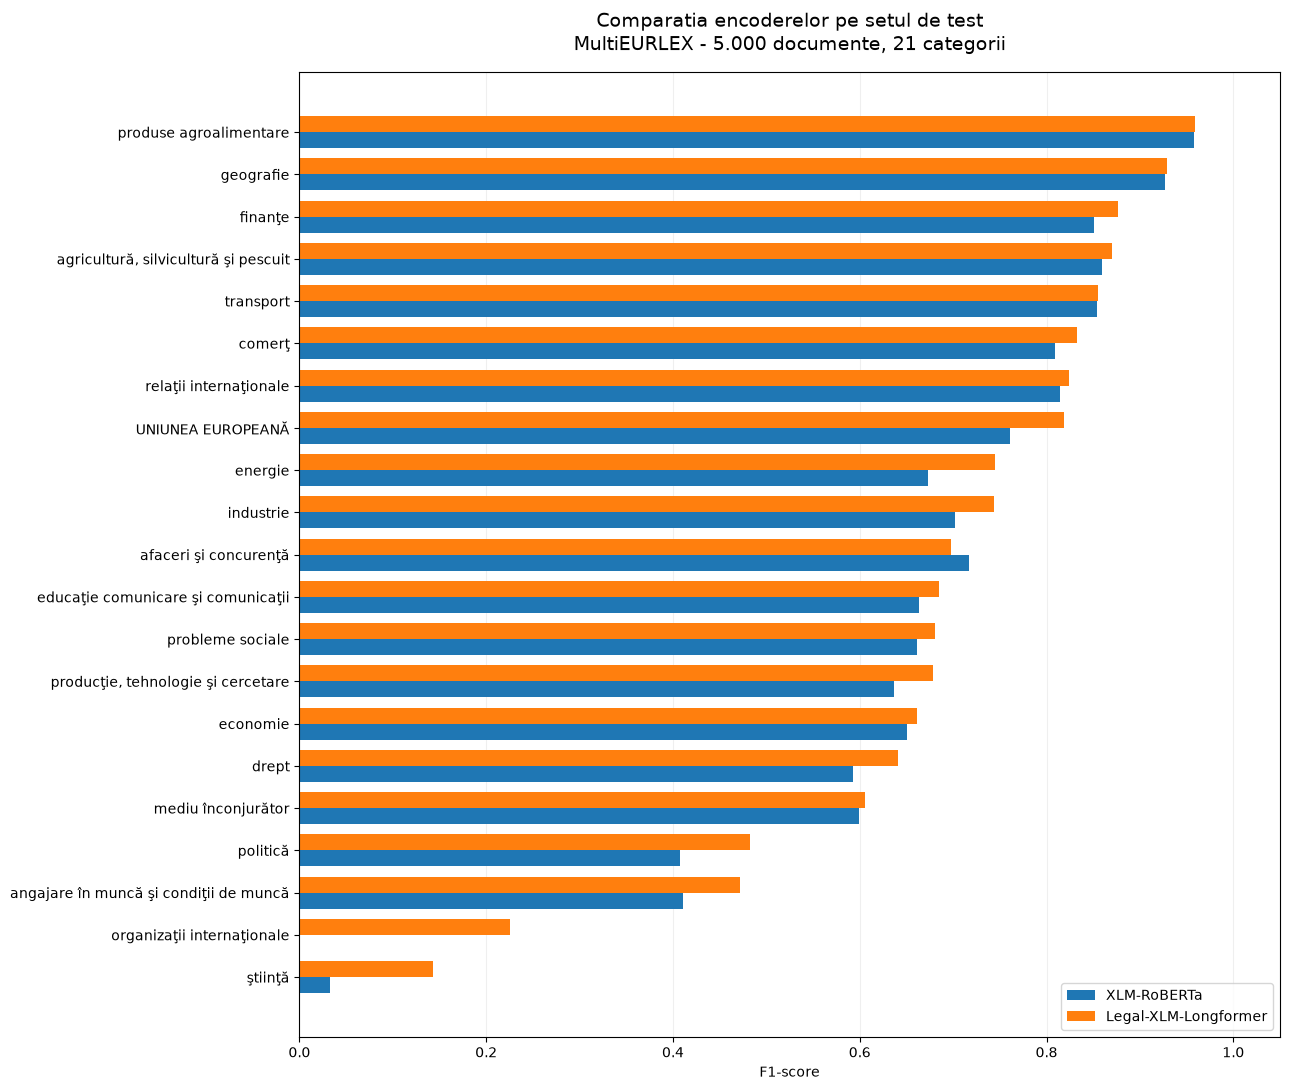

Grafic salvat: /home/emilovici/projects/NLP-Master/Project_multi_eurlex/Results/encoder_test_category_comparison.png


In [27]:

import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("../Results")

# Folosim exclusiv rezultatele deja calculate pe test
plot_df = comparison_test_df.sort_values(
    "longformer_f1",
    ascending=True
)

fig, ax = plt.subplots(figsize=(13, 11))

y = range(len(plot_df))
bar_height = 0.38

ax.barh(
    [i - bar_height / 2 for i in y],
    plot_df["xlm_f1"],
    height=bar_height,
    label="XLM-RoBERTa"
)

ax.barh(
    [i + bar_height / 2 for i in y],
    plot_df["longformer_f1"],
    height=bar_height,
    label="Legal-XLM-Longformer"
)

ax.set_yticks(list(y))
ax.set_yticklabels(plot_df["category"])

ax.set_xlabel("F1-score")
ax.set_xlim(0, 1.05)

ax.set_title(
    "Comparatia encoderelor pe setul de test\n"
    "MultiEURLEX - 5.000 documente, 21 categorii",
    fontsize=14,
    pad=16
)

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

output_path = (
    RESULTS_DIR / "encoder_test_category_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafic salvat:", output_path.resolve())


Observăm că Legal-XLM-Longformer depășește XLM-RoBERTa în 20 dintre cele 21 de categorii, pe setul de test.

Acest lucru este relevant deoarece Longformer îmbunătățește nu doar scorul global, ci și performanța unor categorii dificile.

În același timp, categoriile „știință” și „organizații internaționale” rămân insuficient recunoscute. Așadar, nu putem considera că problema dezechilibrului claselor a fost rezolvată.

Am comparat două modele de tip encoder pentru clasificarea multi-label a documentelor juridice în limba română. Am păstrat aceleași seturi de antrenare, validare și test și am folosit aceleași 21 de categorii EUROVOC.

Am selectat configurațiile pe validation, inclusiv pragurile de clasificare, apoi le-am evaluat fără modificări pe cele 5.000 de documente de test.

Legal-XLM-Longformer a obținut rezultate mai bune decât XLM-RoBERTa atât pentru Micro-F1, cât și pentru Macro-F1. În plus, a depășit modelul de referință în 20 dintre cele 21 de categorii.

Rezultatele justifică alegerea Longformer ca encoder principal, însă nu demonstrează că întregul avantaj provine exclusiv din lungimea mai mare a contextului, deoarece modelele diferă și prin preantrenare și arhitectură.